In [12]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sb 
import joblib, sklearn
import json
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline 
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, precision_recall_curve
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold,RepeatedStratifiedKFold
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance


# ML BACKEND

In [13]:
dataset = pd.read_csv('../data/online_shoppers_intention.csv')
dataset.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [14]:
import joblib
pipe = joblib.load('model/hgb_pipeline.joblib')
print("model loaded")

model loaded


#### Retrain the models/split

In [ ]:
y = dataset['Revenue'].astype(int)
X = dataset.drop(columns='Revenue')

# 60% train / 20% validation / 20% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.6, random_state=13, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=13, stratify=y_temp)


model = clone(pipe)
model.fit(X_train, y_train)

for name, Xs, ys in [("VALIDATION", X_val, y_val), ("TEST", X_test, y_test)]:
    pred = (model.predict_proba(Xs)[:, 1] >= 0.5).astype(int)
    print(f"===== {name} (threshold 0.5) =====")
    print(classification_report(ys, pred))

===== VALIDATION (threshold 0.5) =====
              precision    recall  f1-score   support

           0       0.96      0.88      0.92      2085
           1       0.55      0.82      0.66       381

    accuracy                           0.87      2466
   macro avg       0.76      0.85      0.79      2466
weighted avg       0.90      0.87      0.88      2466

===== TEST (threshold 0.5) =====
              precision    recall  f1-score   support

           0       0.96      0.89      0.93      2084
           1       0.58      0.82      0.68       382

    accuracy                           0.88      2466
   macro avg       0.77      0.85      0.80      2466
weighted avg       0.90      0.88      0.89      2466



#### Part 2: Threshold tuning

In [ ]:


p_val = model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = float(thr[np.argmax(f1)])
print("Best threshold (F1, validation):", round(best_threshold, 3))


p_test = model.predict_proba(X_test)[:, 1]
pred = (p_test >= best_threshold).astype(int)
print(f"\n===== TEST (threshold {best_threshold:.2f}) =====")
print(classification_report(y_test, pred))

# 3. Trade-off table on TEST (for the report)
print("threshold | missed buyers (FN) | wrong alarms (FP)")
for t in [0.3, 0.5, best_threshold, 0.7]:
    pred_t = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    print(f"{t:9.2f} | {fn:18d} | {fp:17d}")

Best threshold (F1, validation): 0.733

===== TEST (threshold 0.73) =====
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      2084
           1       0.68      0.67      0.68       382

    accuracy                           0.90      2466
   macro avg       0.81      0.81      0.81      2466
weighted avg       0.90      0.90      0.90      2466

threshold | missed buyers (FN) | wrong alarms (FP)
     0.30 |                 40 |               429
     0.50 |                 70 |               228
     0.73 |                126 |               118
     0.70 |                113 |               130


#### Feature importance

                    feature  importance     std
0                PageValues      0.5596  0.0120
1                 ExitRates      0.0541  0.0073
2                     Month      0.0477  0.0047
3   ProductRelated_Duration      0.0186  0.0056
4            ProductRelated      0.0160  0.0025
5               BounceRates      0.0135  0.0050
6            Administrative      0.0130  0.0033
7               VisitorType      0.0108  0.0042
8   Administrative_Duration      0.0039  0.0026
9               TrafficType      0.0026  0.0015
10         OperatingSystems      0.0019  0.0010
11                  Weekend      0.0005  0.0004
12               SpecialDay      0.0002  0.0002
13                  Browser     -0.0002  0.0006
14            Informational     -0.0002  0.0003
15                   Region     -0.0002  0.0016
16   Informational_Duration     -0.0021  0.0008


Text(0.5, 1.0, 'Permutation importance (test set)')

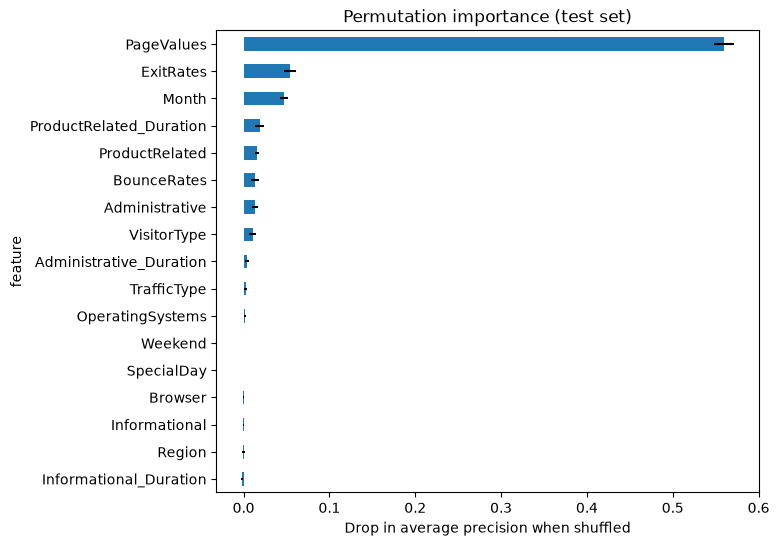

In [17]:
result = permutation_importance(
    model, X_test, y_test,
    scoring='average_precision',
    n_repeats=10, random_state=13, n_jobs=-1)

importance_df = (pd.DataFrame({
        'feature': X_test.columns,
        'importance': result.importances_mean,
        'std': result.importances_std})
    .sort_values('importance', ascending=False)
    .reset_index(drop=True))

print(importance_df.round(4))

importance_df.sort_values('importance').plot.barh(
    x='feature', y='importance', xerr='std', legend=False, figsize=(7, 6))
plt.xlabel('Drop in average precision when shuffled')
plt.title('Permutation importance (test set)')

In [18]:
joblib.dump(model, 'model/hgb_retrained.joblib')
X_test.assign(Revenue=y_test).to_csv('model/test_set.csv', index=False)

with open('model/artifacts.json', 'w') as f:
    json.dump({
        'best_threshold': best_threshold,
        'importance': importance_df.round(6).to_dict(orient='records')
    }, f, indent=2)
print("saved")

saved
